# Night Shift: learning to escape the police

**Deep Learning endterm project**  
**Askat Aubakirov and Alnur Shldenov**  
**Group BDA2403**

We built a small driving game and trained a neural-network agent to survive a police chase and reach a safehouse. We chose **model C after 400,000 additional V2 steps** for the final demonstration. On the recorded V2 test, it won 38 of 40 changed starts and the ordinary fixed start.

This notebook explains the environment and Double DQN, displays the recorded experiments, and runs a short evaluation of the saved C policy. **Run All does not repeat the long training runs.** The complete recorded results are provided with the submission, and optional training cells are clearly marked.

The accompanying PDF is the written report. `Night_Shift_Demo.mp4` is the submission video. All code and data needed by this notebook are in `project_assets.zip`; no external dataset or paid API is used.

## 1. Setup

In Google Colab, open this notebook and run all cells. If the `assets` folder is missing, the next cell downloads the versioned `project_assets.zip` and checks its SHA256. If downloading is unavailable, upload the ZIP from the submission when asked. On a local computer, the ZIP can also be placed beside the notebook. A GPU is useful for long training, but the saved policy can run on a CPU.

The original experiments used PyTorch 2.13.0+cu126. We keep Colab's installed PyTorch rather than installing a Windows CUDA build. Exact replay can vary with software or hardware; the saved experiment tables are kept separate from the new replay check.

In [1]:
# Install only missing packages. Colab normally already has PyTorch and NumPy.
import importlib.util
import subprocess
import sys

packages={'gymnasium':'gymnasium==1.4.0','pygame':'pygame-ce==2.5.8',
          'imageio':'imageio','imageio_ffmpeg':'imageio-ffmpeg',
          'torch':'torch','numpy':'numpy','matplotlib':'matplotlib'}
missing=[package for module,package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])
print('Dependencies ready')

Dependencies ready


In [2]:
ASSET_URL='https://raw.githubusercontent.com/AskatQwerty/Reinforcement/462279a7e2206145c405e8e7c43edc82a26ddc3d/submission/project_assets.zip'
ASSET_SHA256='bb78e147305caa06856484ea5ab9672ed6fa97317c442f88e321e408fdcd5dc2'

from pathlib import Path
import zipfile
import hashlib
import urllib.request

assets=Path.cwd()/'assets'
if not assets.exists():
    archive=Path.cwd()/'project_assets.zip'
    if not archive.exists() and ASSET_URL:
        try:
            print('Downloading the versioned project assets...')
            urllib.request.urlretrieve(ASSET_URL,archive)
        except Exception as error:
            archive.unlink(missing_ok=True)
            print('Automatic download unavailable:',type(error).__name__)
    if not archive.exists():
        try:
            from google.colab import files
        except ImportError:
            raise FileNotFoundError('Put project_assets.zip beside this notebook, then run this cell again.')
        print('Upload project_assets.zip from the submission package.')
        uploaded=files.upload()
        if 'project_assets.zip' not in uploaded:
            raise FileNotFoundError('Please upload the file named project_assets.zip.')
    if ASSET_SHA256 and hashlib.sha256(archive.read_bytes()).hexdigest()!=ASSET_SHA256:
        raise ValueError('The assets ZIP does not match the submitted version.')
    with zipfile.ZipFile(archive) as z:
        # Check paths before extracting the supplied archive.
        for name in z.namelist():
            if not (Path.cwd()/name).resolve().is_relative_to(Path.cwd().resolve()):
                raise ValueError('Unsafe path in the ZIP file')
        z.extractall(Path.cwd())
required=['v2/gym_env.py','v2/train_v2.py','weights/C_V2_400000.pt','evidence.json','curves.json']
for name in required:
    if not (assets/name).is_file():
        raise FileNotFoundError('Missing asset: '+name)
print('Project assets found:',assets.name)

Project assets found: assets


In [3]:
import os
os.environ['PYGAME_HIDE_SUPPORT_PROMPT']='1'
os.environ.setdefault('SDL_VIDEODRIVER','dummy')
import copy
import json
import random
from collections import deque
import numpy as np
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib','inline')
import matplotlib.pyplot as plt
import torch
from torch import nn
import gymnasium as gym
from IPython.display import display,Markdown,Video

sys.path.insert(0,str((assets/'v2').resolve()))
import gym_env
from night_env import GoalShaping

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(1)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
evidence=json.loads((assets/'evidence.json').read_text(encoding='utf-8'))
curves=json.loads((assets/'curves.json').read_text(encoding='utf-8'))
print('Device:',device,'| PyTorch:',torch.__version__)
print('Environment:',gym_env.ENV_ID)

Device: cuda | PyTorch: 2.13.0+cu126
Environment: NightShift-v2


## 2. Environment and connection to Lecture 9

Lecture 9 describes the interaction loop: observe, choose an action, receive a reward, and observe again (slides 13 and 50). Our car follows exactly this loop through Gymnasium `reset()` and `step()`.

The game runs 120 physics updates per second. The agent chooses an action every 0.1 simulated seconds. The safehouse opens after **45 seconds**. Reaching it wins the episode; capture or losing all health ends the episode with a loss. A **180-second external time limit** truncates an unfinished episode.

| Part | Definition |
|---|---|
| Observation | 60 normalized numbers: 23 vehicle/task features, 21 police features, and 16 wall-clearance rays |
| Actions | 15 discrete control combinations: acceleration, steering, braking/reverse, drift and nitro |
| Dynamics | Car inertia, collisions, city geometry and rule-based police pursuit |
| Goal | Maximize discounted reward while escaping successfully |

The 60 numbers include velocity, heading, health, nitro, capture level, the goal direction and opening time. The network does **not** receive camera images. Camera rotation therefore does not change its input. Police routing memory is hidden, so this observation is only partially observed; we do not claim it is a complete Markov state.

**V1 to V2:** in V1, a short acceleration could reduce the capture meter while police remained very close. V2 keeps capture progress while a police car is within 120 pixels; it decays only after all cars are farther away. Capture still grows when a police car is within 72 pixels and the player moves slower than 65 pixels/second. Driving physics, the map, action space and reward formula remain the same.

In [4]:
# A minimal Gymnasium interaction. This does not open a game window.
env=gym.make('NightShift-v2')
observation,info=env.reset(seed=42)
next_observation,reward,terminated,truncated,info=env.step(1)
print('Observation shape:',observation.shape)
print('Actions:',env.action_space.n)
print('One-step reward:',round(reward,5))
print('Terminated:',terminated,'| Truncated:',truncated)
print('Game time:',round(info['elapsed'],2))
env.close()
print('\nAction meanings:')
for i,name in enumerate(gym_env.ACTION_NAMES):
    print(i,name)

Observation shape: (60,)
Actions: 15
One-step reward: 0.005
Terminated: False | Truncated: False
Game time: 0.1

Action meanings:
0 coast
1 accelerate
2 accelerate_left
3 accelerate_right
4 brake_reverse
5 brake_reverse_left
6 brake_reverse_right
7 coast_left
8 coast_right
9 drift_left
10 drift_right
11 nitro
12 nitro_left
13 nitro_right
14 handbrake


### Reward

The original reward adds the following terms at each decision:

| Term | Reward |
|---|---:|
| Survive before the safehouse opens | +0.05 per simulated second |
| Time after opening | -0.05 per simulated second |
| Progress toward the safehouse after opening | 0.002 × reduction in distance |
| Lost health | -0.1 × health lost |
| Increase in capture meter | -0.5 × increase |
| Win / loss | +20 / -10 |

Training configurations B and C also use a distance potential:

\[
\Phi(s)=-\frac{d(s,\mathrm{safehouse})}{\mathrm{world\ diagonal}},\qquad
r_{train}=r_{base}+8[\gamma\Phi(s')-\Phi(s)].
\]

This gives feedback before the exit opens and helps with the sparse-goal problem discussed in Lecture 9 (slide 47). Potential is set to zero at a real terminal state, but not at a time-limit truncation. The extra term follows the potential-based shaping form of Ng et al. (1999). The base progress reward is a separate heuristic; we do not claim a general policy-invariance guarantee for the whole game. **All evaluation tables and reward curves below use the original reward, without the extra potential term.**

## 3. From Q-learning to a neural network

Lecture 9 introduces discounted return, Q-values and epsilon-greedy exploration (slides 17, 38–43). We keep these ideas and replace the Q-table with a neural network, since continuous car positions and velocities do not fit a small table.

\[
G_t=\sum_{k=0}^{\infty}\gamma^k r_{t+k+1},\qquad
Q(s,a)\approx\mathbb{E}[G_t\mid s_t=s,a_t=a].
\]

The network takes 60 observation values and outputs 15 Q-values, one for each action. Hidden layers use ReLU; the output layer is linear because Q-values may be negative. We compare two configurations of the same Double DQN algorithm:

| Model | Hidden layers | Output |
|---|---|---|
| B | 64, 64 | 15 Q-values |
| C | 128, 128, 64 | 15 Q-values |

DQN adds a replay buffer and a target network (Mnih et al., 2013; 2015). Double DQN separates the action selection from its target value estimate (van Hasselt et al., 2015). These additions go beyond the lecture's tabular example, but the Bellman target is the same basic idea.

In [5]:
class DQN(nn.Module):
    def __init__(self,hidden_sizes):
        super().__init__()
        layers=[]
        previous=60
        for size in hidden_sizes:
            layers.extend([nn.Linear(previous,size),nn.ReLU()])
            previous=size
        layers.append(nn.Linear(previous,15))
        self.layers=nn.Sequential(*layers)

    def forward(self,x):
        return self.layers(x)

model_b=DQN([64,64]).to(device)
demo_model=DQN([128,128,64]).to(device)
example=torch.as_tensor(observation,dtype=torch.float32,device=device).unsqueeze(0)
print('Input:',tuple(example.shape),'| Output:',tuple(demo_model(example).shape))
print('B parameters:',sum(p.numel() for p in model_b.parameters()))
print('C parameters:',sum(p.numel() for p in demo_model.parameters()))

Input: (1, 60) | Output: (1, 15)
B parameters: 9039
C parameters: 33551


### Epsilon-greedy actions and replay memory

With probability epsilon, the agent explores a random action. Otherwise it takes the largest predicted Q-value. We store transitions `(state, action, reward, next_state, terminated)` and sample random groups to reduce correlation between consecutive driving steps.

The next cell collects 200 transitions just to demonstrate the method. These are not the data used for the reported long experiments.

In [6]:
def choose_action(model,state,epsilon):
    if random.random()<epsilon:
        return random.randrange(15)
    with torch.no_grad():
        x=torch.as_tensor(state,dtype=torch.float32,device=device).unsqueeze(0)
        return int(model(x).argmax(1).item())

memory=deque(maxlen=50000)
train_env=GoalShaping(gym.make('NightShift-v2'),scale=8,gamma=0.995)
state,info=train_env.reset(seed=42)
for step in range(200):
    action=choose_action(demo_model,state,epsilon=1.0)
    next_state,reward,terminated,truncated,info=train_env.step(action)
    memory.append((state.copy(),action,reward,next_state.copy(),terminated))
    state=next_state
    if terminated or truncated:
        state,info=train_env.reset(seed=43+step)
train_env.close()
print('Saved transitions:',len(memory))
print('State shapes:',memory[0][0].shape,memory[0][3].shape)

Saved transitions: 200
State shapes: (60,) (60,)


### Target network, loss and one update

The online network chooses the next action and the target network evaluates it:

\[
a^*=\arg\max_a Q_\theta(s',a),\qquad
y=r+\gamma(1-\mathrm{terminated})Q_{\theta^-}(s',a^*).
\]

We minimize the Smooth L1 (Huber) loss between $Q_\theta(s,a)$ and $y$ with Adam. Gradients do not pass through the target. The target network is copied from the online network every 1,000 environment steps in the long runs.

`terminated` removes the future value after capture, destruction or a win. An external time limit is `truncated`, so the target still bootstraps there. This distinction follows the Gymnasium API. This demonstration updates a separate randomly initialized network; it never changes the saved C policy.

In [7]:
target_model=copy.deepcopy(demo_model).eval()
target_model.requires_grad_(False)
optimizer=torch.optim.Adam(demo_model.parameters(),lr=0.0001)

def update_network(model,target,optimizer,memory,gamma=0.995,batch_size=64):
    batch=random.sample(list(memory),batch_size)
    states,actions,rewards,next_states,terminals=zip(*batch)
    states=torch.as_tensor(np.array(states),dtype=torch.float32,device=device)
    actions=torch.tensor(actions,dtype=torch.long,device=device)
    rewards=torch.tensor(rewards,dtype=torch.float32,device=device)
    next_states=torch.as_tensor(np.array(next_states),dtype=torch.float32,device=device)
    terminals=torch.tensor(terminals,dtype=torch.float32,device=device)

    # Current predictions for the actions stored in memory.
    predicted=model(states).gather(1,actions[:,None]).squeeze(1)
    with torch.no_grad():
        # Double DQN: online network selects, target network evaluates.
        next_actions=model(next_states).argmax(1,keepdim=True)
        next_q=target(next_states).gather(1,next_actions).squeeze(1)
        expected=rewards+gamma*(1-terminals)*next_q

    loss=nn.functional.smooth_l1_loss(predicted,expected)
    optimizer.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(),10)
    optimizer.step()
    return loss.item(),expected[:5].detach().cpu().numpy()

loss,example_targets=update_network(demo_model,target_model,optimizer,memory)
print('First five targets:',np.round(example_targets,4))
print('Loss after one sampled update:',round(loss,6))

First five targets: [0.1987 0.2048 0.2066 0.2345 0.181 ]
Loss after one sampled update: 0.028428


### Optional short training loop

The function below shows the complete interaction-and-update loop in one place. It is a **small new demonstration**, with warmup reduced to 128 steps; it does not recreate the historical scores. Leave `RUN_SHORT_TRAINING=False` for the normal submission run. A 2,000-step example is far too short to establish good driving.

The unchanged full training program is also included in `assets/v2/train_v2.py`. It contains the original fixed settings, 50% fixed / 50% varied starting positions, checkpoint saving, optimizer and replay state, and diagnostic checks. Checkpoint selection is implemented in `assets/v2/eval_v2.py`. Its full 400,000-step reproduction is opt-in because it can take a long time.

In [8]:
def train_short(hidden_sizes,total_steps=2000):
    model=DQN(hidden_sizes).to(device)
    target=copy.deepcopy(model).eval().requires_grad_(False)
    optimizer=torch.optim.Adam(model.parameters(),lr=0.0001)
    replay=deque(maxlen=50000)
    env=GoalShaping(gym.make('NightShift-v2'),scale=8,gamma=0.995)
    state,info=env.reset(seed=42)
    episode_reward=0.0
    history=[]
    try:
        for step in range(1,total_steps+1):
            epsilon=1.0-0.95*min(1,step/total_steps)
            action=choose_action(model,state,epsilon)
            next_state,reward,terminated,truncated,info=env.step(action)
            replay.append((state.copy(),action,reward,next_state.copy(),terminated))
            episode_reward+=info['base_reward']
            state=next_state
            if len(replay)>=128 and step%4==0:
                update_network(model,target,optimizer,replay)
            if step%1000==0:
                target.load_state_dict(model.state_dict())
            if terminated or truncated:
                history.append({'step':step,'reward':episode_reward,'success':info['success']})
                offset=(0,0,0) if random.random()<0.5 else (
                    random.uniform(-30,30),random.uniform(-30,30),random.uniform(-10,10))
                state,info=env.reset(seed=42+step,options={'start_offset':offset})
                episode_reward=0.0
    finally:
        env.close()
    return model,history

RUN_SHORT_TRAINING=False
if RUN_SHORT_TRAINING:
    short_b,history_b=train_short([64,64])
    short_c,history_c=train_short([128,128,64])
    print('New short demonstration episodes:',len(history_b),len(history_c))
else:
    print('Short training skipped. Recorded experiment results are shown below.')

RUN_FULL_V2_TRAINING=False
if RUN_FULL_V2_TRAINING:
    for name in ['B','C']:
        subprocess.check_call([sys.executable,str(assets/'v2'/'train_v2.py'),
                               '--model',name,'--steps','400000'])

RUN_FULL_V1_TRAINING=False
if RUN_FULL_V1_TRAINING:
    for name in ['B','C']:
        subprocess.check_call([sys.executable,str(assets/'v1'/'train_from_scratch.py'),
                               '--model',name,'--steps','300000'])

Short training skipped. Recorded experiment results are shown below.


## 4. Recorded experiment design

The main controlled network-size comparison is **V1 B versus V1 C**: both started from scratch and used the same settings except hidden-layer sizes. The original overnight target was 400,000 steps, but the runs were stopped early. We compare both at the same **300,000-step analysis budget**. V1 used 20 changed validation starts per checkpoint: the highest validation score selected C at 300,000 steps. A supplementary fixed-start eligibility criterion, declared before the held-out tests, selected B at 250,000 steps for ordinary-start deployment. Both selected checkpoints were then tested on the same 40 held-out starts. The curves show the common 300,000-step interval, including B's later training after its selected checkpoint.

For V2, we transferred those V1 weights and gave each model **400,000 additional steps** with new replay memory and optimizer state. The V2 comparison measures adaptation of these two candidates; it is not an architecture-only experiment because their selected V1 pretraining budgets differ.

For V2, checkpoints were selected using five diagnostic starts: fixed-start success first, then diagnostic win rate, mean original reward, and later step. Step 0 was eligible. The 40 final changed starts were not used for checkpoint selection. All final tests use greedy actions with no learning.

In [9]:
# Display the recorded settings, not settings inferred from the final scores.
def config_value(config,key):
    value=config.get(key,'see source config')
    return str(value)

keys=['hidden_sizes','gamma','learning_rate','batch_size','memory_capacity',
      'warmup_steps','train_every','target_update','epsilon_start','epsilon_end',
      'epsilon_decay_steps','potential_scale']
lines=['| Setting | V1 B | V1 C | V2 B | V2 C |','|---|---|---|---|---|']
configs=evidence['configs']
for key in keys:
    values=[config_value(configs[version][model],key) for version,model in
            [('v1','B'),('v1','C'),('v2','B'),('v2','C')]]
    lines.append('| '+key+' | '+' | '.join(values)+' |')
display(Markdown('\n'.join(lines)))

| Setting | V1 B | V1 C | V2 B | V2 C |
|---|---|---|---|---|
| hidden_sizes | [64, 64] | [128, 128, 64] | [64, 64] | [128, 128, 64] |
| gamma | 0.995 | 0.995 | 0.995 | 0.995 |
| learning_rate | 0.0001 | 0.0001 | 0.0001 | 0.0001 |
| batch_size | 64 | 64 | 64 | 64 |
| memory_capacity | 50000 | 50000 | 50000 | 50000 |
| warmup_steps | 2000 | 2000 | 2000 | 2000 |
| train_every | 4 | 4 | 4 | 4 |
| target_update | 1000 | 1000 | 1000 | 1000 |
| epsilon_start | 1.0 | 1.0 | 0.4 | 0.4 |
| epsilon_end | 0.1 | 0.1 | 0.05 | 0.05 |
| epsilon_decay_steps | 100000 | 100000 | 200000 | 200000 |
| potential_scale | 8.0 | 8.0 | 8.0 | 8.0 |

### Original reward versus training steps

Light lines show episode returns and dark lines show a 20-episode moving average. Random exploratory actions are present during training, so these curves are not greedy-policy test scores. We have full V1 B/C episode histories and V2 C history. Only the V2 B diagnostic summary and final weights were transferred; we do not invent its missing episode curve.

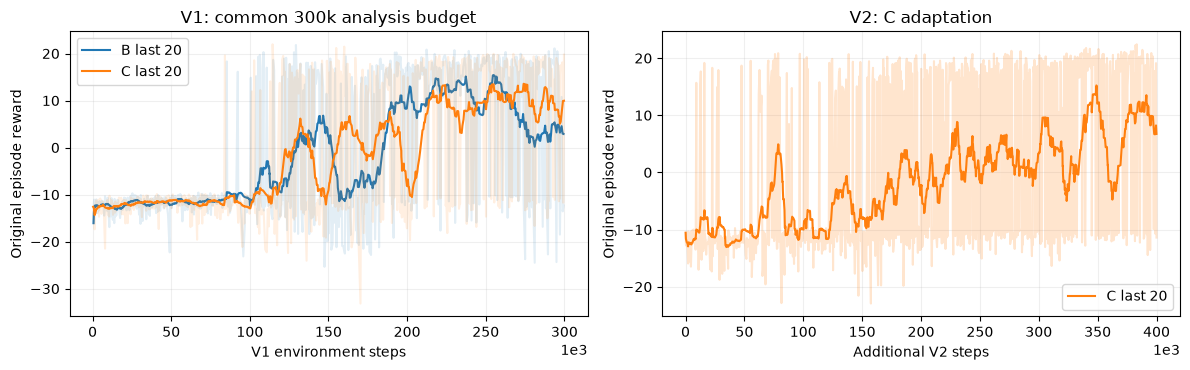

In [10]:
def moving_average(values,window=20):
    return [float(np.mean(values[max(0,i-window+1):i+1])) for i in range(len(values))]

fig,axes=plt.subplots(1,2,figsize=(12,3.8))
for name,color in [('B','tab:blue'),('C','tab:orange')]:
    rows=curves['v1'][name]
    steps=[row['step'] for row in rows]
    rewards=[row['base_reward'] for row in rows]
    axes[0].plot(steps,rewards,color=color,alpha=.12)
    axes[0].plot(steps,moving_average(rewards),color=color,label=name+' last 20')
rows=curves['v2']['C']
steps=[row['step'] for row in rows]
rewards=[row['base_reward'] for row in rows]
axes[1].plot(steps,rewards,color='tab:orange',alpha=.2)
axes[1].plot(steps,moving_average(rewards),color='tab:orange',label='C last 20')
axes[0].set(title='V1: common 300k analysis budget',xlabel='V1 environment steps',ylabel='Original episode reward')
axes[1].set(title='V2: C adaptation',xlabel='Additional V2 steps',ylabel='Original episode reward')
for ax in axes:
    ax.ticklabel_format(axis='x',style='sci',scilimits=(3,3))
    ax.legend()
    ax.grid(alpha=.2)
fig.tight_layout()
plt.show()

### V1 held-out results

These scores use the selected V1 checkpoints on 40 held-out starting perturbations per model. Starting position changes are small variations on the same city map, not new maps. Mean and standard deviation describe original episode reward. The ordinary fixed start is reported separately because repeating it with different seeds produces the same deterministic situation.

In [11]:
# Compare the two architectures at exactly the same V1 step count first.
lines=['| V1 checkpoint | Validation wins | Reward mean ± SD |',
       '|---|---:|---:|']
for row in evidence['v1']['validation']:
    if row['model'] in ['B_300k','C_300k']:
        lines.append(f"| {row['model']} | {row['wins']}/{row['episodes']} | "
                     f"{row['mean_reward']:.3f} ± {row['std_reward']:.3f} |")
display(Markdown('**Common 300k budget: validation set used during selection**\n\n'+'\n'.join(lines)))

lines=['| Selected V1 policy | Held-out wins | Reward mean ± SD | Mean winning time |',
       '|---|---:|---:|---:|']
for row in evidence['v1']['heldout']:
    lines.append(f"| {row['model']} | {row['wins']}/{row['episodes']} | "
                 f"{row['mean_reward']:.3f} ± {row['std_reward']:.3f} | {row['mean_win_seconds']:.2f} s |")
display(Markdown('\n'.join(lines)))
print('Selected policies on the ordinary fixed start:')
for name,row in evidence['v1']['selected_fixed'].items():
    print(name,':','won' if row['success'] else 'lost',f"in {row['seconds']:.2f} seconds")

**Common 300k budget: validation set used during selection**

| V1 checkpoint | Validation wins | Reward mean ± SD |
|---|---:|---:|
| B_300k | 9/20 | -2.520 ± 16.769 |
| C_300k | 16/20 | 12.054 ± 12.004 |

| Selected V1 policy | Held-out wins | Reward mean ± SD | Mean winning time |
|---|---:|---:|---:|
| B_250k | 33/40 | 12.719 ± 11.540 | 57.59 s |
| C_300k | 36/40 | 15.184 ± 9.148 | 46.97 s |

Selected policies on the ordinary fixed start:
B250 : won in 73.27 seconds
C300 : lost in 21.55 seconds


### V2 before and after adaptation

Both original policies and both 400k policies were evaluated on the same main computer, same V2 rules and same 50 cases: 10 fixed-start repeats and 40 distinct changed starts. The fixed repeats are one deterministic scenario. The changed starts vary position by at most 30 pixels and heading by at most 10 degrees.

The imported B weights reproduced all five reported 400k diagnostic episodes, so the poor B result was reproduced after transfer. B's best policy under the predefined diagnostic rule remains its original V1 policy (V2 step 0). B at 400k is shown as the latest trained policy, not mislabeled as its best checkpoint.

In [12]:
names={'B_before':'B original / diagnostic-selected',
       'B_after':'B latest after 400k V2',
       'C_before':'C original',
       'C_after':'C selected after 400k V2'}
lines=['| Policy | Starts | Wins | Reward mean ± SD | Mean winning time |',
       '|---|---|---:|---:|---:|']
for policy in evidence['v2']['policies']:
    for group in ['fixed','changed']:
        row=policy['summary'][group]
        seconds=row['mean_win_seconds']
        duration='No wins' if seconds is None else f'{seconds:.2f} s'
        lines.append(f"| {names[policy['key']]} | {group} | {row['wins']}/{row['episodes']} | "
                     f"{row['mean_reward']:.3f} ± {row['std_reward']:.3f} | {duration} |")
display(Markdown('\n'.join(lines)))

| Policy | Starts | Wins | Reward mean ± SD | Mean winning time |
|---|---|---:|---:|---:|
| B original / diagnostic-selected | fixed | 10/10 | 18.292 ± 0.000 | 51.39 s |
| B original / diagnostic-selected | changed | 32/40 | 9.828 ± 12.021 | 51.04 s |
| B latest after 400k V2 | fixed | 0/10 | -10.162 ± 0.000 | No wins |
| B latest after 400k V2 | changed | 13/40 | -1.596 ± 13.725 | 51.35 s |
| C original | fixed | 0/10 | -11.060 ± 0.000 | No wins |
| C original | changed | 29/40 | 8.604 ± 14.145 | 46.89 s |
| C selected after 400k V2 | fixed | 10/10 | 19.955 ± 0.000 | 48.33 s |
| C selected after 400k V2 | changed | 38/40 | 17.351 ± 6.849 | 56.79 s |

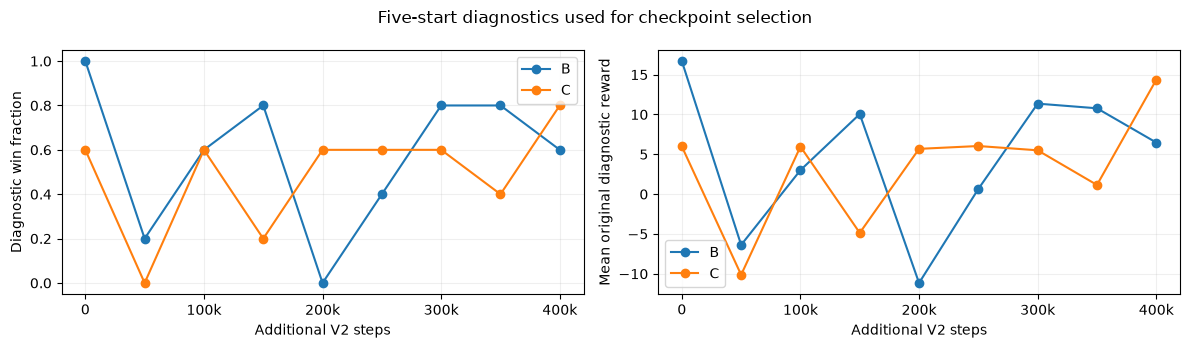

In [13]:
fig,axes=plt.subplots(1,2,figsize=(12,3.5))
for model,rows in evidence['v2']['diagnostics'].items():
    steps=[row['step'] for row in rows]
    axes[0].plot(steps,[row['success_rate'] for row in rows],marker='o',label=model)
    axes[1].plot(steps,[row['mean_reward'] for row in rows],marker='o',label=model)
axes[0].set(ylabel='Diagnostic win fraction',ylim=(-.05,1.05))
axes[1].set(ylabel='Mean original diagnostic reward')
for ax in axes:
    ax.set_xlabel('Additional V2 steps')
    ax.set_xticks([0,100000,200000,300000,400000],['0','100k','200k','300k','400k'])
    ax.grid(alpha=.2)
    ax.legend()
fig.suptitle('Five-start diagnostics used for checkpoint selection')
fig.tight_layout()
plt.show()

## 5. Run the selected C policy

The next cell loads only the saved parameter tensors. The selected network is separate from the demonstration network that received a training update earlier.

The following replay check evaluates **10 distinct cases from the recorded changed-start test set**. It demonstrates that the submitted policy and environment execute together. These cases have already been tested: this is a repeat audit, not a new independent hold-out set, and it does not replace the saved 40-case result. Results on another Colab runtime may differ slightly because of numeric differences.

In [14]:
selected_c=DQN([128,128,64]).to(device)
weights=torch.load(assets/'weights'/'C_V2_400000.pt',map_location='cpu',weights_only=True)
selected_c.load_state_dict(weights,strict=True)
selected_c.eval().requires_grad_(False)
print('Loaded C: V1 300k + V2 400k steps')
print('Model input/output:',tuple(example.shape),tuple(selected_c(example).shape))

Loaded C: V1 300k + V2 400k steps
Model input/output: (1, 60) (1, 15)


In [15]:
def evaluate_policy(model,cases):
    env=gym.make('NightShift-v2')
    rows=[]
    try:
        with torch.inference_mode():
            for i,case in enumerate(cases):
                state,info=env.reset(seed=case['seed'],options={'start_offset':case['case']})
                total=0.0
                while True:
                    action=choose_action(model,state,epsilon=0.0)
                    state,reward,terminated,truncated,info=env.step(action)
                    total+=reward
                    if terminated or truncated:
                        break
                rows.append({'reward':total,'success':bool(info['success']),'seconds':info['elapsed']})
                print(f"Case {i+1}/{len(cases)}: {info['status']}, {info['elapsed']:.1f} s")
    finally:
        env.close()
    return rows

audit_cases=[case for case in evidence['v2']['protocol']['cases'] if case['group']=='changed'][:10]
audit_rows=evaluate_policy(selected_c,audit_cases)
audit_rewards=[row['reward'] for row in audit_rows]
print('Replay wins:',sum(row['success'] for row in audit_rows),'/',len(audit_rows))
print('Replay original reward mean:',round(float(np.mean(audit_rewards)),3))
print('Replay original reward SD:',round(float(np.std(audit_rewards)),3))

Case 1/10: won, 95.8 s


Case 2/10: won, 86.6 s


Case 3/10: won, 46.9 s


Case 4/10: won, 45.0 s


Case 5/10: won, 45.0 s


Case 6/10: won, 62.4 s


Case 7/10: won, 45.0 s


Case 8/10: won, 47.6 s


Case 9/10: won, 46.5 s


Case 10/10: won, 142.1 s
Replay wins: 10 / 10
Replay original reward mean: 17.782
Replay original reward SD: 3.414


### Saved video

The full demonstration movie is attached separately as `Night_Shift_Demo.mp4`. This notebook also includes the original uncut fixed-start C run. It is a demonstration and is not an extra test episode in the result averages.

In [16]:
video=assets/'videos'/'C_V2_400000.mp4'
if not video.is_file():
    raise FileNotFoundError('The C video is missing from project_assets.zip')
display(Video(filename=str(video),embed=True,width=640))

## 6. Discussion and conclusion

The controlled V1 comparison changed network size while keeping other settings fixed and using a common 300k analysis budget. The held-out selected C policy won 36/40, compared with 33/40 for B. Selected checkpoint steps differ (C300k versus B250k), so the held-out table compares selected policies rather than two exact 300k snapshots. This is evidence from one training seed and a small test set, not proof that a deeper network will always be better.

The V1 game also showed why environment design matters: the capture meter could decrease without a real escape from nearby police. V2 changed that rule while keeping the observation and action formats compatible. On matched V2 changed starts, C improved from 29/40 to 38/40; B's latest policy declined from 32/40 to 13/40. Longer training therefore did not guarantee a better policy. Keeping earlier checkpoints protected the stronger original B policy. The instability is consistent with a known RL difficulty from Lecture 9, but one run does not identify whether overfitting, unstable value estimates or another cause explains B's decline.

We choose C at V2 step 400k for the final demonstration. It also wins the ordinary fixed start, which the original C policy failed. Future work should use several independent training seeds, new city layouts and more diagnostic starts. Recurrent observations could help with hidden police routing state. We would test these changes with a fresh final test set.

**Limitations:** the test variations use one map; fixed repeats are not independent scenarios; V2 starts from unequal selected V1 budgets; training occurred on different GPUs; and the full V2 B replay/optimizer/episode history has not been transferred. B's received weights and diagnostic history are preserved, and its final performance was measured locally. We compare measured reward and success, not training speed across computers.

## References

1. Zholtayev, D. (n.d.). *AI in robotics, Lecture 9*. Course lecture slides. Slides 13–26, 38–43 and 47–51 motivated the RL loop, Q-learning, exploration and evaluation.
2. Mnih, V., et al. (2013). *Playing Atari with deep reinforcement learning*. https://arxiv.org/abs/1312.5602
3. Mnih, V., et al. (2015). Human-level control through deep reinforcement learning. *Nature, 518*, 529–533. https://doi.org/10.1038/nature14236
4. van Hasselt, H., Guez, A., & Silver, D. (2015). *Deep reinforcement learning with Double Q-learning*. https://arxiv.org/abs/1509.06461
5. Ng, A. Y., Harada, D., & Russell, S. (1999). Policy invariance under reward transformations: Theory and application to reward shaping. *ICML*. https://ai.stanford.edu/~ang/papers/shaping-icml99.pdf
6. Farama Foundation. (n.d.). *Gymnasium Env API*. https://gymnasium.farama.org/api/env/
7. Paszke, A., & Towers, M. (n.d.). *Reinforcement learning (DQN) tutorial*. PyTorch tutorials. https://docs.pytorch.org/tutorials/intermediate/reinforcement_q_learning.html

The game, numerical observation design, V1/V2 capture experiment and experiment analysis are project-specific. The replay, target network and tensor update follow standard DQN ideas in the cited papers and PyTorch tutorial; this project uses Double DQN targets, shaped training rewards and original-reward evaluation.